The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


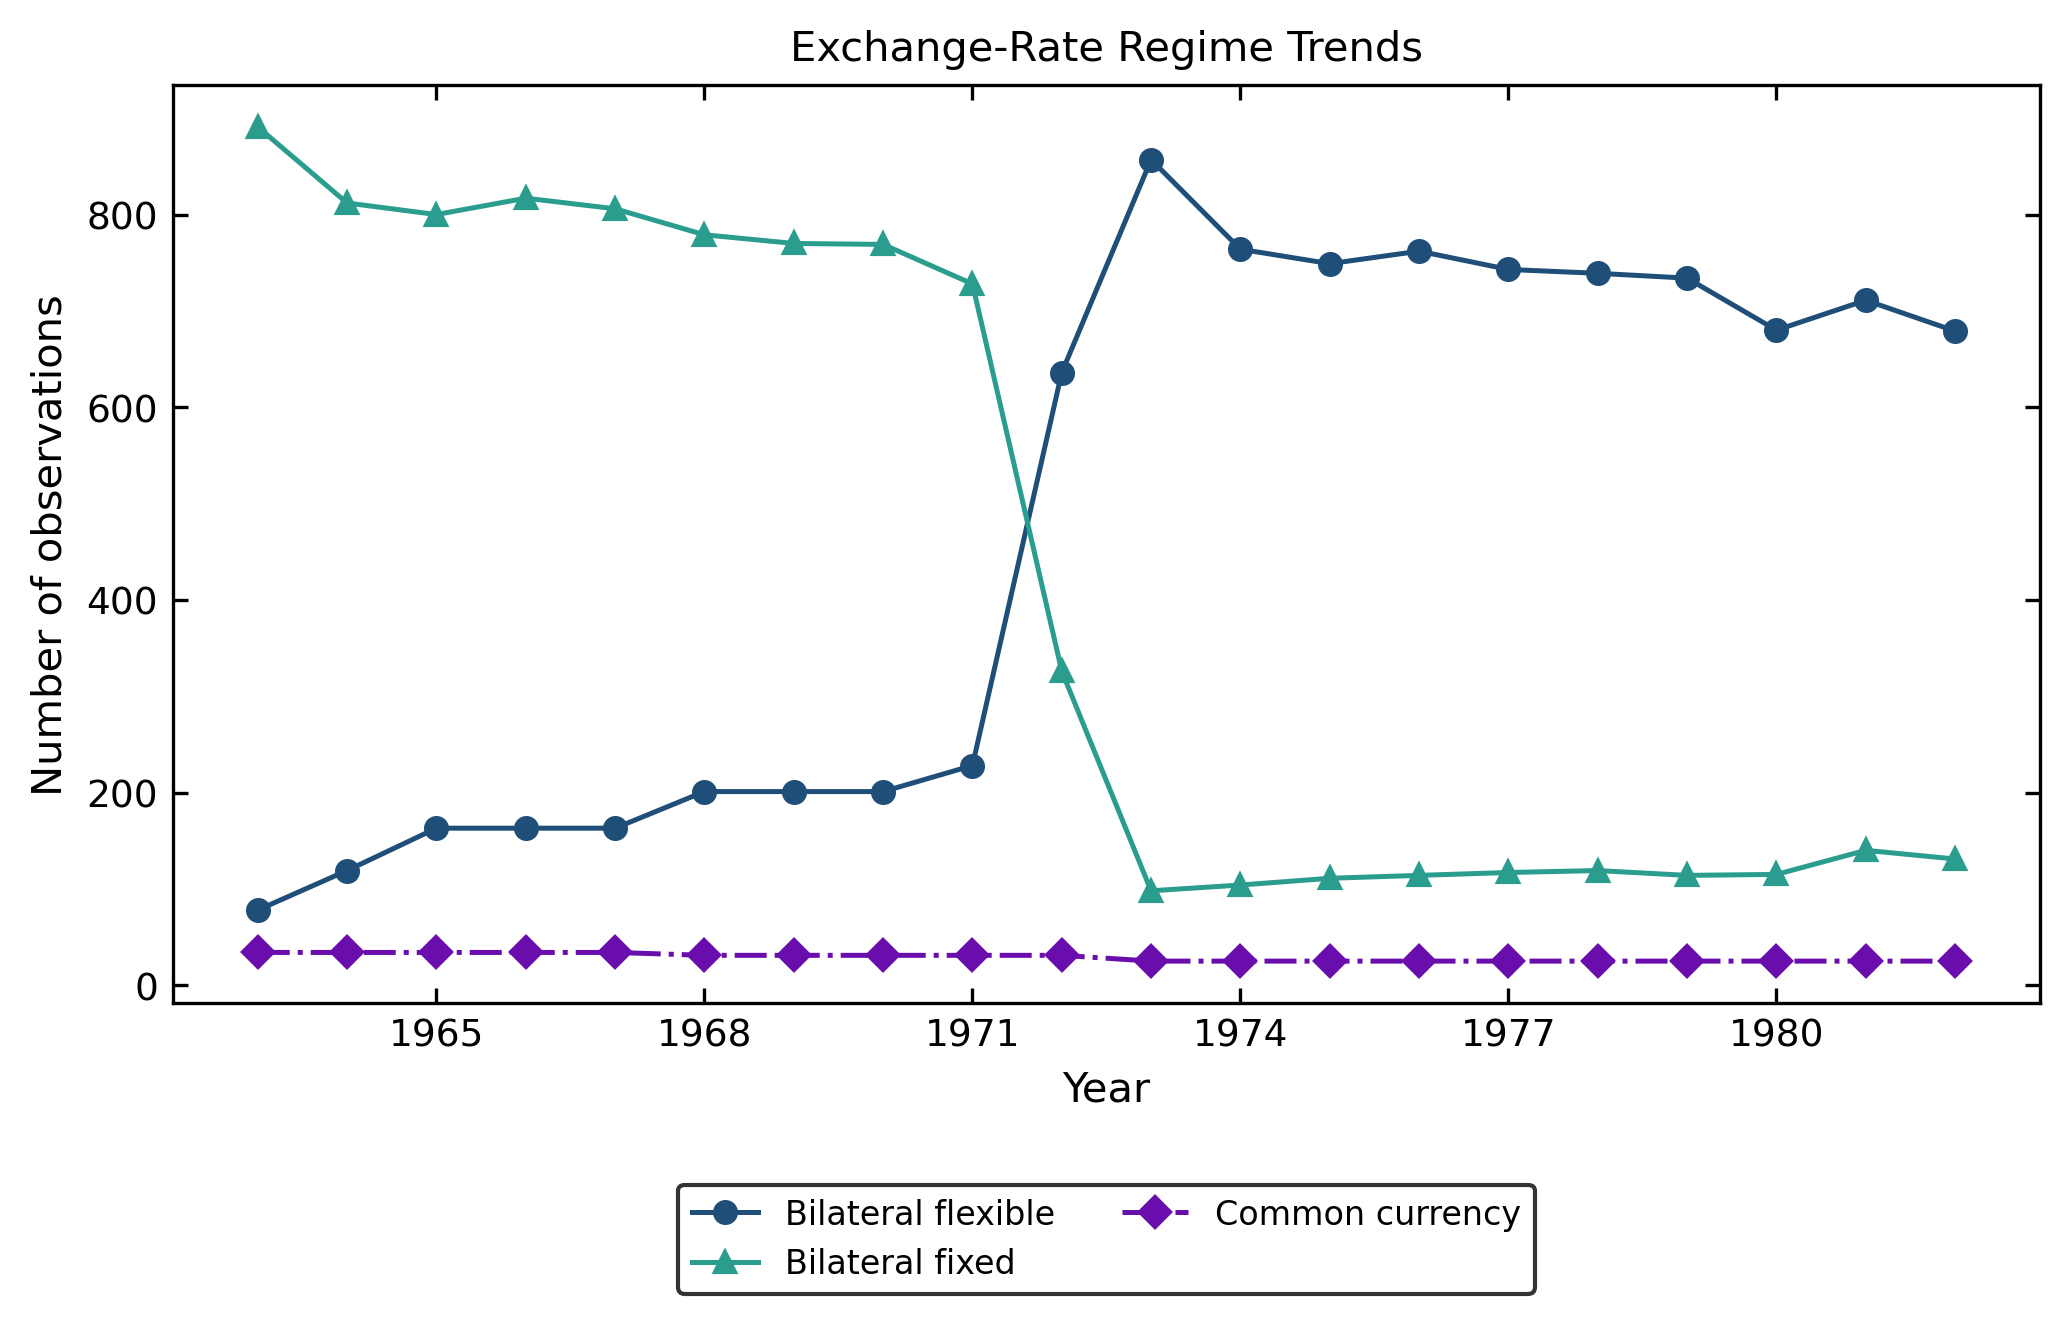

In [4]:
#Figure 1
from matplotlib.ticker import FormatStrFormatter, MultipleLocator
import matplotlib.pyplot as plt
import pandas as pd

panel = pd.read_csv(r"C:\Users\HP\Dropbox\CFA paper\panel.csv")

fixed_trend = panel.groupby(["year", "fixed"]).size().unstack(fill_value=0)

fixed_trend = fixed_trend.rename(columns={0: "Bilateral flexible",1: "Bilateral fixed",
                                          "freely falling": "Freely falling",})

common_currency_trend = ( panel.groupby("year")["common_currency"].sum().rename("Common currency"))

trend = pd.concat([fixed_trend, common_currency_trend], axis=1)

# Highly distinct colors, shapes, and line styles to avoid visual similarity
series_styles = { "Bilateral flexible": {
        "marker": "o", "color": "#1f4e79",
        "linestyle": "-", },  
    "Bilateral fixed": {"marker": "^","color": "#2a9d8f",
                        "linestyle": "-",},  
    "Freely falling": { "marker": "s",
        "color": "#e76f51","linestyle": "--",},
    "Common currency": { "marker": "D","color": "#6a0dad",
        "linestyle": "-.",}, }

# Plot setup with standard academic dimensions
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

for col in trend.columns:
  style = series_styles.get(col, {"marker": "o", "color": "black", "linestyle": "-"})
  ax.plot(
      trend.index,trend[col],
      marker=style["marker"],
      color=style["color"],linestyle=style["linestyle"],
      linewidth=1.2,markersize=5,
      label=col,)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")
ax.spines["top"].set_visible(True)
ax.spines["right"].set_visible(True)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")
ax.tick_params(direction="in", top=True, right=True, labelsize=9)

ax.xaxis.set_major_locator(MultipleLocator(3))
ax.xaxis.set_major_formatter(FormatStrFormatter("%d"))

ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Number of observations", fontsize=10)
ax.set_title("Exchange-Rate Regime Trends", fontsize=10)

# Clean, bordered horizontal legend positioned beneath the plot (2 columns layout)
ax.legend( loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=True,
    facecolor="white",
    edgecolor="black",
    fontsize=8,)

plt.tight_layout()
plt.tight_layout()  

# Save EPS (vector format)
plt.savefig(r"exchange_rate_regime_trends.eps",
    format="eps", bbox_inches="tight",)

In [ ]:
#Table 1
#removing the freely falling countries

panel_5_3 = pd.read_csv(r"panel_5_3.csv")
panel_5_3["ln_trade_avg"] = np.log1p(panel_5_3["trade_avg"])
fixed_num = pd.to_numeric(panel_5_3["fixed"], errors="coerce")
df1 = panel_5_3.loc[fixed_num.notna()].copy()

df1["fixed"] = fixed_num.loc[fixed_num.notna()].astype("int8")

#PPML no pair FE
model1 = pf.fepois("trade_avg ~ Distw + Contig + Comlang + trade_agreement + "
    "common_currency:post + fixed:post| "
    "iso_o^period + iso_d^period",
    data=df1,vcov={"CRV1": "pair_ID"})

#PPML with pair FE
model1 = pf.fepois(
    "trade_avg ~ trade_agreement + common_currency:post + fixed:post | "
    "iso_o^period + iso_d^period + pair_ID",
    data=df1,vcov={"CRV1": "pair_ID"})

#OLS no pair FE
model_ols = pf.feols(
    "ln_trade_avg ~ Distw + Contig + Comlang + trade_agreement + "
    "common_currency:post + fixed:post| "
    "iso_o^period + iso_d^period",
    data=df1,vcov={"CRV1": "pair_ID"})

#OLS with pair FE
model_ols = pf.feols(
    "ln_trade_avg ~ trade_agreement + "
    "common_currency:post + fixed:post| "
    "iso_o^period + iso_d^period + pair_ID",
    data=df1, vcov={"CRV1": "pair_ID"},
    demeaner=pf.LsmrDemeaner(
        fixef_maxiter=100000,
        fixef_atol=1e-6,
        fixef_btol=1e-6))

In [ ]:
#Table 2: excluding endogenous
# Exclude countries
exclude_countries = ["GHA", "NGA", "TZA", "UGA", "ZMB"]

df1_subset = df1[
    ~df1["iso_o"].isin(exclude_countries) &
    ~df1["iso_d"].isin(exclude_countries)].copy()

print("Original observations:", len(panel_5_3))
print("After dropping missing fixed:", len(df1))
print("After excluding countries:", len(df1_subset))
print("Excluded observations:", len(df1) - len(df1_subset))

# PPML 1: no pair FE
model_ppml1 = pf.fepois(
    "trade_avg ~ Distw + Contig + Comlang + trade_agreement + "
    "common_currency:post + fixed:post | "
    "iso_o^period + iso_d^period",
    data=df1_subset,vcov={"CRV1": "pair_ID"} )

print(model_ppml1.summary())

# PPML 2: With pair FE
model_ppml2 = pf.fepois(
    "trade_avg ~ trade_agreement + common_currency:post + fixed:post | "
    "iso_o^period + iso_d^period + pair_ID",
    data=df1_subset, vcov={"CRV1": "pair_ID"},
    demeaner=pf.LsmrDemeaner(
        fixef_maxiter=100000,
        fixef_atol=1e-6,
        fixef_btol=1e-6))

# OLS 1: Gravity controls, no pair FE
model_ols1 = pf.feols(
    "ln_trade_avg ~ Distw + Contig + Comlang + trade_agreement + "
    "common_currency:post + fixed:post | "
    "iso_o^period + iso_d^period",
    data=df1_subset,
    vcov={"CRV1": "pair_ID"})


# OLS 2: With pair FE
model_ols2 = pf.feols(
    "ln_trade_avg ~ trade_agreement + common_currency:post + fixed:post | "
    "iso_o^period + iso_d^period + pair_ID",
    data=df1_subset,
    vcov={"CRV1": "pair_ID"})

In [ ]:
#Table 3: Oil producing nations
model1 = pf.fepois(
    "trade_avg ~ common_currency:post:oil_pair + fixed:post:oil_pair | "
    "iso_o^period + iso_d^period + pair_ID",
    data=df1,
    vcov={"CRV1": "pair_ID"})


In [ ]:
#Appendix Table: Simple trade average
panel_5_3_simple["ln_trade_avg"] = np.log1p(
    panel_5_3_simple["trade_avg"])

fixed_num = pd.to_numeric(panel_5_3_simple["fixed"], errors="coerce")
df1 = panel_5_3_simple.loc[fixed_num.notna()].copy()
df1["fixed"] = fixed_num.loc[fixed_num.notna()].astype("int8")

# PPML 1: Gravity controls, without pair FE
model_ppml1 = pf.fepois(
    "trade_avg ~ Distw + Contig + Comlang + trade_agreement + "
    "common_currency:post + fixed:post | "
    "iso_o^period + iso_d^period",
    data=df1,
    vcov={"CRV1": "pair_ID"})

# PPML 2: With pair FE
model_ppml2 = pf.fepois(
    "trade_avg ~ trade_agreement + common_currency:post + fixed:post | "
    "iso_o^period + iso_d^period + pair_ID",
    data=df1, vcov={"CRV1": "pair_ID"},
    demeaner=pf.LsmrDemeaner(
        fixef_maxiter=100000,
        fixef_atol=1e-6,
        fixef_btol=1e-6))

# OLS 1: Gravity controls, without pair FE
model_ols1 = pf.feols(
    "ln_trade_avg ~ Distw + Contig + Comlang + trade_agreement + "
    "common_currency:post + fixed:post | "
    "iso_o^period + iso_d^period",
    data=df1,
    vcov={"CRV1": "pair_ID"})

# OLS 2: With pair FE, using LSMR demeaning
model_ols2 = pf.feols(
    "ln_trade_avg ~ trade_agreement + common_currency:post + fixed:post | "
    "iso_o^period + iso_d^period + pair_ID",
    data=df1,
    vcov={"CRV1": "pair_ID"})